# comparing_model9 — do expression errors point toward the cross-cell average?

This notebook tests three related questions on **Enformer-grid CAGE** and, separately,
**Borzoi-grid CAGE**: (1) are cell-specific activation and silence harder to predict?
(2) do signed errors point toward the measured other-cell average? (3) at similar measured
GM12878 expression, do predictions still depend on that average?

All eight Enformer/cis-Mamba arms and all five Borzoi/cis-Mamba arms from model8 are included.
No retraining, AlphaGenome, or cross-assay RAMPAGE comparison is introduced here.
This is a new diagnostic analysis, **not a Kathail/AlphaGenome reproduction**.

**Run all cells in the caduceus environment.** Every analysis function is defined here;
there are no project-helper imports or runner dependencies. Inputs are the promoter
matrices built by `prepare_model8.py` (in `comparing_model8_results/`), plus original bin-level arrays.
Figures are saved to `comparing_model9_results/`.

### Readouts and prespecified decisions

- Reuse model8's GENCODE v49 annotation-selected representative transcript, same held-out genes,
  ±512-bp promoter windows, and connected components of overlapping 524-kb inputs for uncertainty.
  Enformer is unstranded/128 bp; Borzoi is strand matched/32 bp, on its native processed target scale.
  No cross-grid ranking of absolute metrics is appropriate.
- The **bin-level test** uses unique genomic bins inside those selected promoters. Active is
  signal ≥1; silent is <0.2; intermediate bins are excluded from classification. These are inherited
  operational CAGE cutoffs, not calibrated detection limits, especially on Borzoi's different scale.
  Other-cell background is the arithmetic mean of the 637 non-GM12878 same-assay tracks.
  Low background is below promoter-bin p50; high is at/above p90. Sensitivities vary both cutoffs.
  This is a model7-style R1/R2 test on a different, fixed representative-promoter population,
  **not an exact reproduction of model7's all-transcript-TSS-bin population**. No ATAC selection.
- For amplitude and expression matching, use `y=log2(promoter_sum+1)` and
  `mu=mean(log2(other_promoter_sum+1))`, as in model8. The arithmetic-bin mean used for the
  classification challenge is intentionally different. Log of the arithmetic promoter mean is
  included as a sensitivity. All models use the same observed reference; no predicted-panel mean.
- Classification thresholds are chosen by **five-fold genomic-block cross-fitting**: each model's
  cutoff is the 95th percentile of silent-bin predictions in the other four folds; call active only
  when prediction is strictly greater. The same cutoff serves every background stratum in a held-out
  fold. This targets ≤5% calibration FPR, not guaranteed test FPR. It is internal cross-fitting on
  saved test outputs, **not an independent validation-set benchmark**.
- 1,000 paired genomic-block bootstrap draws for rates, signed errors, and conditional coefficients;
  500 for AUROC. The same block weights apply jointly to both classes and all models.
  Intervals condition on chosen strata and fitted cross-fold thresholds; they exclude threshold-fitting,
  training-seed, and replicate uncertainty. No multiplicity-adjusted significance claims.

**Interpretation boundary:** selection on noisy measured expression can create apparent shrinkage.
Independent expression replicates are not established for these arrays, so selection/evaluation use
one measurement. Results are descriptive evidence consistent with a cross-cell-average bias, not proof
of its mechanism. cis-Mamba receives measured accessibility; Enformer/Borzoi are sequence-only.
Therefore a cis-Mamba advantage cannot be attributed solely to single-task training. The Borzoi cis-Mamba
checkpoint is distinct from the Enformer-grid checkpoint. Borzoi's inherited split filter permits some
input/training-label overlap; a strict no-overlap sensitivity is included.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display, Markdown

ROOT = Path('/data1/lesliec/sarthak/caduceus')
HERE = ROOT/'notebooks/model_eval/cage_rna'
BASE = HERE/'comparing_model8_results'
OUT = HERE/'comparing_model9_results'
OUT.mkdir(exist_ok=True)
DATA = Path('/data1/lesliec/sarthak/data')
MO, BOR = DATA/'joint_playground/model_out', DATA/'borzoi'
PAD, SEED, N_BOOT, N_AUC_BOOT, N_FOLDS = 512, 20260925, 1000, 500, 5
MIN_N, MIN_BLOCKS = 20, 5
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
                     'font.size':10, 'figure.facecolor':'white'})
pd.set_option('display.max_columns', 16)
def load_npz(path):
    with np.load(path) as f:return {k:f[k] for k in f.files}

p_e=pd.read_csv(BASE/'promoters.tsv',sep='\t')
a_e=load_npz(BASE/'cage_promoter_inputs.npz')
a_e.update(load_npz(BASE/'extensions/enformer_extra_inputs.npz'))
p_b=pd.read_csv(BASE/'extensions/borzoi_promoters.tsv',sep='\t')
a_b=load_npz(BASE/'extensions/borzoi_inputs.npz')
PANELS={'Enformer':(p_e,a_e),'Borzoi':(p_b,a_b)}
MODELS={k:[m for m in a if m!='measured'] for k,(p,a) in PANELS.items()}
COLORS=dict(zip(MODELS['Enformer'],['#177A3B','#A32316','#63BF82','#83BCA3','#E2603F','#C93B22','#E39B74','#A36860']))
COLORS.update(dict(zip(MODELS['Borzoi'],['#177A3B','#12456F','#7FB3DE','#2E7EBD','#526C85'])))
COLORS['Observed other-track mean']='#777777'
COLORS['Zero expression']='#BBBBBB'

FRAMES={}
for grid,(p,a) in PANELS.items():
    keep=p['pad'].to_numpy()==PAD
    f=p.loc[keep].reset_index(drop=True).copy()
    raw=a['measured'][keep]
    assert raw.shape==(len(f),638) and not f.gene_id.duplicated().any()
    assert np.isfinite(raw).all() and (raw>=0).all()
    other=np.arange(638)!=435
    f['raw_y']=raw[:,435]
    f['y']=np.log2(f.raw_y+1)
    f['mu']=np.log2(raw[:,other]+1).mean(axis=1)
    f['mu_arithmetic']=np.log2(raw[:,other].mean(axis=1)+1)
    f['d']=f.y-f.mu
    for m in MODELS[grid]:
        v=a[m][keep]
        assert v.shape==(len(f),) and np.isfinite(v).all() and (v>=0).all()
        f[m]=np.log2(v+1)
    f['Observed other-track mean']=f.mu
    f['Zero expression']=0.
    FRAMES[grid]=f
display(pd.DataFrame([dict(grid=g,genes=len(f),blocks=f.block.nunique(),models=len(MODELS[g])) for g,f in FRAMES.items()]))

Validated 8 cache hashes and 27,445 original source fingerprints.


,grid,genes,blocks,models
0,Enformer,1797,87,8
1,Borzoi,1934,160,5


## 1. Recover bin-level values and verify them against promoter sums

Bins shared by multiple selected promoters are scored once (strand is part of the identity for
Borzoi). The source-row/bin mapping and fold assignment are exported. Each model's newly extracted
bin values must sum back to the model8 promoter values, and measured GM12878 and other-cell means
must agree with the measured panel. These checks also audit the cached background means.

In [2]:
def bin_index(f, grid):
    pieces=[]
    for r in f.itertuples():
        bins=np.arange(r.bin_start,r.bin_end)
        pieces.append(pd.DataFrame(dict(row=r.enformer_row,bin=bins,chrom=r.chrom,
            start=r.output_start+bins*(128 if grid=='Enformer' else 32),
            strand=r.strand if grid=='Borzoi' else '.',block=r.block,gene_id=r.gene_id,
            strand_col=0 if r.strand=='+' else 1)))
    full=pd.concat(pieces,ignore_index=True)
    unique=full.drop_duplicates(['chrom','start','strand']).reset_index(drop=True)
    assert not unique.duplicated(['row','bin','strand']).any()
    return full,unique

E_SPECS={
 'cis-Mamba':(MO/'GM12878_no_mlm_predictions.npy',None),
 'Enformer':(MO/'enformer_test_track5110.npy',None),
 'cis-Mamba (no pretraining)':(MO/'nopretrain_predictions.npy',None),
 'cis-Mamba (8 CTs)':(MO/'immune_CAGE_predictions.npy',None),
}
for label,stem in [('Enformer retrained (1 CT, 768ch)','enformer_retrained_gm12878'),
                   ('Enformer retrained (1 CT, 1536ch)','enformer_retrained_n1_1536'),
                   ('Enformer retrained (16 CTs)','enformer_retrained_n16'),
                   ('Enformer retrained (42 CTs)','enformer_retrained_n42')]:
    path=MO/stem/f'{stem}_cage_predictions.npy'
    a=np.load(path,mmap_mode='r'); col=None
    if a.ndim==3:
        t=pd.read_csv(MO/stem/f'{stem}_cage_tracks.csv')
        t=t[(t.cell_type=='GM12878')&(t.assay=='cage')]
        assert len(t)==1 and int(t.target_index.iloc[0])==5110
        col=int(t.column.iloc[0])
    E_SPECS[label]=(path,col)
B_SPECS={
 'cis-Mamba (Borzoi grid)':(MO/'borzoi_gm12878_cage_ep4_outputs.npy','h1w2'),
 'Borzoi pretrained':(BOR/'model_outputs_fold3_gm12878CAGE.npy','hw2'),
 'Borzoi LoRA':(BOR/'model_outputs/borzoi_finetuned_gm12878_lorav2.npy','hw3'),
 'Borzoi full FT':(BOR/'model_outputs/borzoi_finetuned_gm12878_trunk.npy','hw3'),
 'Borzoi from scratch':(BOR/'model_outputs/borzoi_finetuned_gm12878_scratch.npy','hw3'),
}

def extract(a,idx,grid,col=None):
    r,b=idx.row.to_numpy(),idx.bin.to_numpy()
    if grid=='Enformer':
        if a.ndim==3:a=a[:,:,0 if col is None else col]
        assert a.shape==(1937,896)
        return np.asarray(a[r,b],float)
    if a.ndim==4:a=a[:,0]
    assert a.shape[:2]==(6888,6144)
    return np.asarray(a[r,b,idx.strand_col.to_numpy()],float)

def gate_sums(values,full,f,expected,label,rtol=1e-5,atol=1e-5):
    sums=pd.Series(values).groupby(full.gene_id.to_numpy(),sort=False).sum().reindex(f.gene_id).to_numpy()
    assert np.allclose(sums,expected,rtol=rtol,atol=atol), f'Promoter/bin mismatch: {label}, max={np.max(np.abs(sums-expected))}'

BINS={}
for grid,f in FRAMES.items():
    full,idx=bin_index(f,grid)
    targetpath=MO/('GM12878_base_targets_conv.npy' if grid=='Enformer' else 'borzoi_gm12878_cage_ep4_targets.npy')
    truth=np.load(targetpath,mmap_mode='r')
    gate_sums(extract(truth,full,grid),full,f,f.raw_y.to_numpy(),grid+' target')
    idx['truth']=extract(truth,idx,grid)
    specs=E_SPECS if grid=='Enformer' else B_SPECS
    for model,(path,col) in specs.items():
        a=np.load(path,mmap_mode='r')
        if grid=='Borzoi':col=None
        gate_sums(extract(a,full,grid,col),full,f,np.exp2(f[model].to_numpy())-1,model)
        idx[model]=extract(a,idx,grid,col)
        del a
    if grid=='Enformer':
        avg=np.load(DATA/'enformer/data/avg_cage_test_all.npy',mmap_mode='r')
        full_avg=np.maximum((avg[full.row,full.bin].astype(float)*638-extract(truth,full,grid))/637,0)
        idx['background']=np.maximum((avg[idx.row,idx.bin].astype(float)*638-idx.truth)/637,0)
    else:
        avgfile=BOR/'borzoi_fold3_CAGE_avg.npz'
        full_avg=np.zeros(len(full));idx['background']=0.
        with np.load(avgfile) as arrays:
            meta=json.loads(str(arrays['meta']))
            assert meta['gm_slot']==435 and meta['n_cell_types']==638
            for strand,key in [(0,'avg_plus_loo'),(1,'avg_minus_loo')]:
                avg=arrays[key]
                mask=full.strand_col.to_numpy()==strand
                full_avg[mask]=avg[full.row.to_numpy()[mask],full.bin.to_numpy()[mask]]
                mask=idx.strand_col.to_numpy()==strand
                idx.loc[mask,'background']=avg[idx.loc[mask,'row'],idx.loc[mask,'bin']]
                del avg
    gate_sums(full_avg,full,f,np.exp2(f.mu_arithmetic.to_numpy())-1,grid+' other mean',rtol=3e-5,atol=2e-4)
    assert np.isfinite(idx[['truth','background']+MODELS[grid]].to_numpy()).all()
    assert (idx[['truth','background']+MODELS[grid]].to_numpy()>=0).all()
    # Balance block folds by bin count, using a deterministic random tie order.
    counts=idx.groupby('block').size()
    rng=np.random.default_rng(SEED)
    ordered=counts.iloc[rng.permutation(len(counts))].sort_values(ascending=False,kind='stable')
    sizes=np.zeros(N_FOLDS,int);assignment={}
    for b,n in ordered.items():
        fold=int(np.argmin(sizes));assignment[b]=fold;sizes[fold]+=n
    idx['fold']=idx.block.map(assignment)
    assert idx.groupby('block').fold.nunique().max()==1
    idx['Observed other-track mean']=idx.background
    BINS[grid]=idx
    print(grid,':',len(idx),'unique bins;',idx.block.nunique(),'blocks; fold sizes',sizes.tolist(),'; all sum checks passed')

Enformer : 13320 unique bins; 87 blocks; fold sizes [2664, 2667, 2663, 2661, 2665] ; all sum checks passed
Borzoi : 61036 unique bins; 160 blocks; fold sizes [12205, 12201, 12216, 12206, 12208] ; all sum checks passed


## 2. Disagreement AUROC, missed activation, and false activation

The original mean baseline has AUROC zero on R2 **by construction**, not because a statistical
mechanism has been established. Random ranking has expected AUROC 0.5. A below-chance model result
on this challenge is evidence of systematic ranking failure on this selected population.

Report active-bin recall and silent-bin false-positive rate separately for low and high background,
using identical cross-fitted model thresholds across strata. Intermediate-background bins remain
in the overall analysis and threshold calibration. These are bin detection rates, not called-peak rates.
The two background groups can also differ in GM12878 signal strength; these rate differences alone
do not control for that. The expression-matched analysis below addresses this separately.
AUROC is threshold free. Comparisons with fewer than 20 members of either class or five blocks per
class retain counts but have suppressed AUROC/intervals. Rate strata use the same support rule.

In [3]:
BOOT={}
def boot_for(f,n=N_BOOT):
    keys,ids=np.unique(f.block.to_numpy(),return_inverse=True)
    if len(keys) not in BOOT:
        rng=np.random.default_rng(SEED)
        BOOT[len(keys)]=rng.multinomial(len(keys),np.full(len(keys),1/len(keys)),size=N_BOOT)
    return ids,BOOT[len(keys)][:n]

def ci(v):
    v=np.asarray(v);ok=np.isfinite(v)
    return (*np.quantile(v[ok],[.025,.975]),int(ok.sum())) if ok.mean()>=.9 else (np.nan,np.nan,int(ok.sum()))

def supported(f,mask):return int(mask.sum())>=MIN_N and f.loc[mask,'block'].nunique()>=MIN_BLOCKS

def mean_boot(f,values,mask):
    ids,w=boot_for(f); mask=np.asarray(mask,bool);v=np.asarray(values,float)
    nb=w.shape[1]
    counts=np.bincount(ids[mask],minlength=nb)
    sums=np.bincount(ids[mask],weights=v[mask],minlength=nb)
    den=w@counts
    with np.errstate(divide='ignore',invalid='ignore'):draws=(w@sums)/den
    return (float(v[mask].mean()) if mask.any() else np.nan),draws

def weighted_auc(scores,labels,weights=None):
    scores=np.asarray(scores);labels=np.asarray(labels,bool)
    weights=np.ones(len(scores)) if weights is None else np.asarray(weights,float)
    order=np.argsort(scores,kind='stable');s=scores[order];lab=labels[order];w=weights[order]
    starts=np.r_[0,np.flatnonzero(np.diff(s))+1]
    pos=np.add.reduceat(w*lab,starts);neg=np.add.reduceat(w*(~lab),starts)
    den=pos.sum()*neg.sum()
    return float(np.sum(pos*(np.cumsum(neg)-neg+.5*neg))/den) if den>0 else np.nan

def auc_boot(f,scores,pos,neg,n=N_AUC_BOOT):
    keep=pos|neg
    if not (supported(f,pos) and supported(f,neg)):return np.nan,np.full(n,np.nan)
    ids,w=boot_for(f,n);ids=ids[keep];s=np.asarray(scores)[keep];lab=pos[keep]
    order=np.argsort(s,kind='stable');s=s[order];lab=lab[order];ids=ids[order]
    starts=np.r_[0,np.flatnonzero(np.diff(s))+1]
    result=[]
    for weight in w:
        v=weight[ids];p=np.add.reduceat(v*lab,starts);q=np.add.reduceat(v*(~lab),starts)
        den=p.sum()*q.sum()
        result.append(np.sum(p*(np.cumsum(q)-q+.5*q))/den if den>0 else np.nan)
    return weighted_auc(np.asarray(scores)[keep],pos[keep]),np.asarray(result)

def groups(f,active=1.,silent=.2,low_q=.5,high_q=.9):
    low,high=np.quantile(f.background,[low_q,high_q])
    assert high>low, 'Background quantiles do not separate; inspect tied signals.'
    lo=(f.background.to_numpy()<low) if low>0 else (f.background.to_numpy()==0)
    hi=f.background.to_numpy()>=high
    pos=f.truth.to_numpy()>=active;neg=f.truth.to_numpy()<silent
    return pos,neg,lo,hi,dict(active=active,silent=silent,background_low=float(low),background_high=float(high),low_q=low_q,high_q=high_q)

RATE_ROWS=[];AUC_ROWS=[];THRESHOLDS=[];COUNTS=[];RATE_DRAWS={};AUC_DRAWS={};CALLS={}
for grid,f in BINS.items():
    pos,neg,low,high,cut=groups(f)
    names=MODELS[grid]+['Observed other-track mean']
    for label,mask in [('All active',pos),('Active / low background',pos&low),('Active / high background',pos&high),
                       ('All silent',neg),('Silent / low background',neg&low),('Silent / high background',neg&high)]:
        COUNTS.append(dict(grid=grid,stratum=label,n=int(mask.sum()),blocks=f.loc[mask,'block'].nunique(),supported=supported(f,mask),**cut))
    for model in names:
        score=f[model].to_numpy();called=np.zeros(len(f),bool)
        for fold in range(N_FOLDS):
            cal=(f.fold.to_numpy()!=fold)&neg;test=f.fold.to_numpy()==fold
            assert cal.sum()>=MIN_N and not np.any(cal&test)
            threshold=float(np.quantile(score[cal],.95,method='higher'))
            called[test]=score[test]>threshold
            THRESHOLDS.append(dict(grid=grid,model=model,fold=fold,threshold=threshold,
                n_calibration_silent=int(cal.sum()),calibration_fpr=float(np.mean(score[cal]>threshold))))
        CALLS[grid,model]=called
        for kind,base in [('Recall',pos),('FPR',neg)]:
            for bg,mask in [('All',base),('Low',base&low),('High',base&high)]:
                point,draws=mean_boot(f,called.astype(float),mask)
                ok=supported(f,mask)
                if not ok:point=np.nan;draws[:]=np.nan
                lower,upper,valid=ci(draws)
                RATE_ROWS.append(dict(grid=grid,model=model,metric=kind,background=bg,value=point,lo=lower,hi=upper,
                    n=int(mask.sum()),blocks=f.loc[mask,'block'].nunique(),valid_draws=valid,status='estimated' if ok else 'insufficient support'))
                RATE_DRAWS[grid,model,kind,bg]=draws
        for label,p,n in [('All classified promoter bins',pos,neg),('Disagreement R2',pos&low,neg&high)]:
            point,draws=auc_boot(f,score,p,n)
            lower,upper,valid=ci(draws)
            AUC_ROWS.append(dict(grid=grid,model=model,subset=label,auroc=point,lo=lower,hi=upper,
                n_positive=int(p.sum()),n_negative=int(n.sum()),positive_blocks=f.loc[p,'block'].nunique(),
                negative_blocks=f.loc[n,'block'].nunique(),valid_draws=valid,status='estimated' if np.isfinite(point) else 'insufficient support'))
            AUC_DRAWS[grid,model,label]=draws
    if supported(f,pos&low) and supported(f,neg&high):
        assert weighted_auc(f.loc[(pos&low)|(neg&high),'background'],(pos&low)[(pos&low)|(neg&high)])==0
    print(grid,'classification complete')
RATES=pd.DataFrame(RATE_ROWS); AUCS=pd.DataFrame(AUC_ROWS); COUNTS=pd.DataFrame(COUNTS)
display(COUNTS[['grid','stratum','n','blocks','supported']])
display(AUCS[['grid','model','subset','auroc','lo','hi','n_positive','n_negative','status']].round(3))

Enformer classification complete
Borzoi classification complete


,grid,stratum,n,blocks,supported
0,Enformer,All active,5230,78,True
1,Enformer,Active / low background,627,57,True
2,Enformer,Active / high background,1248,60,True
3,Enformer,All silent,6077,86,True
4,Enformer,Silent / low background,4869,82,True
5,Enformer,Silent / high background,44,18,True
6,Borzoi,All active,10256,131,True
7,Borzoi,Active / low background,155,54,True
8,Borzoi,Active / high background,4855,121,True
9,Borzoi,All silent,45763,160,True


,grid,model,subset,auroc,lo,hi,n_positive,n_negative,status
0,Enformer,cis-Mamba,All classified promoter bins,0.941,0.934,0.948,5230,6077,estimated
1,Enformer,cis-Mamba,Disagreement R2,0.691,0.593,0.796,627,44,estimated
2,Enformer,Enformer,All classified promoter bins,0.928,0.921,0.937,5230,6077,estimated
3,Enformer,Enformer,Disagreement R2,0.550,0.449,0.676,627,44,estimated
4,Enformer,cis-Mamba (no pretraining),All classified promoter bins,0.930,0.922,0.938,5230,6077,estimated
5,Enformer,cis-Mamba (no pretraining),Disagreement R2,0.676,0.610,0.745,627,44,estimated
6,Enformer,cis-Mamba (8 CTs),All classified promoter bins,0.937,0.931,0.945,5230,6077,estimated
7,Enformer,cis-Mamba (8 CTs),Disagreement R2,0.528,0.445,0.613,627,44,estimated
8,Enformer,"Enformer retrained (1 CT, 768ch)",All classified promoter bins,0.887,0.876,0.899,5230,6077,estimated
9,Enformer,"Enformer retrained (1 CT, 768ch)",Disagreement R2,0.400,0.284,0.530,627,44,estimated


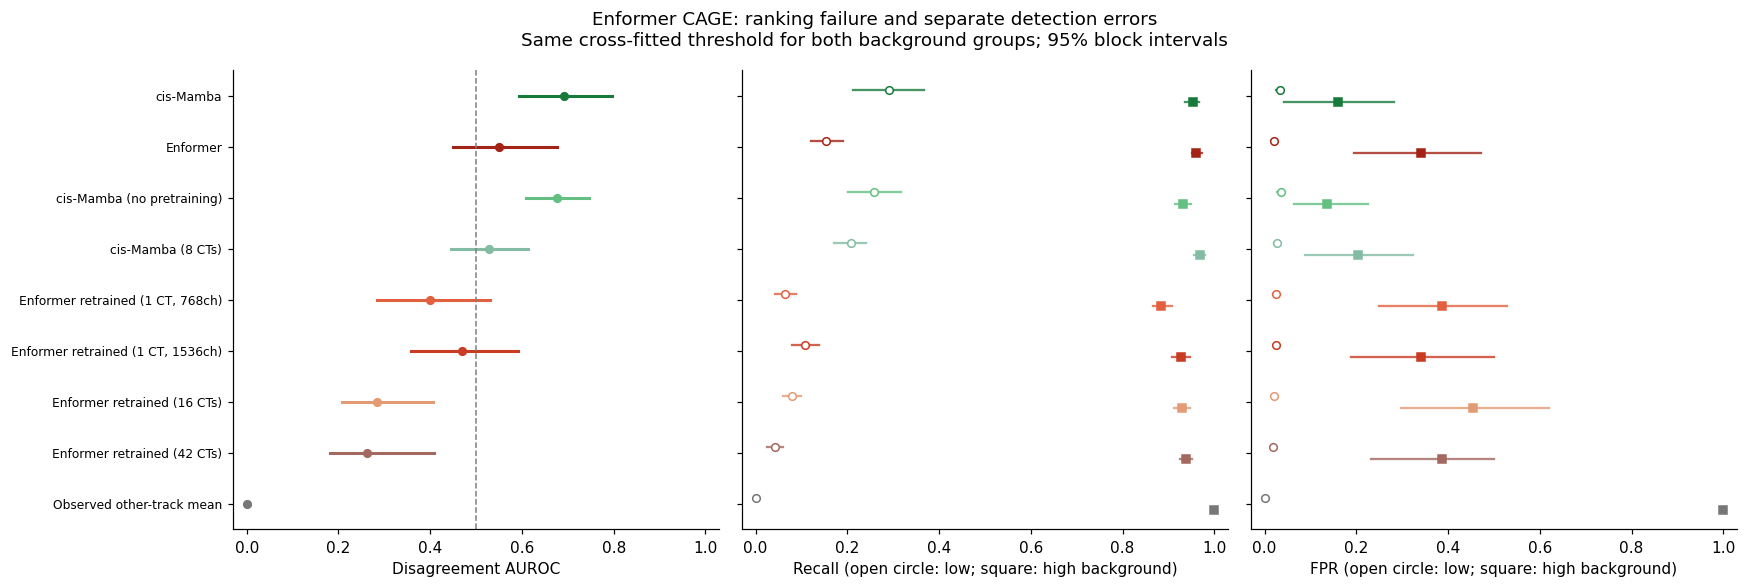

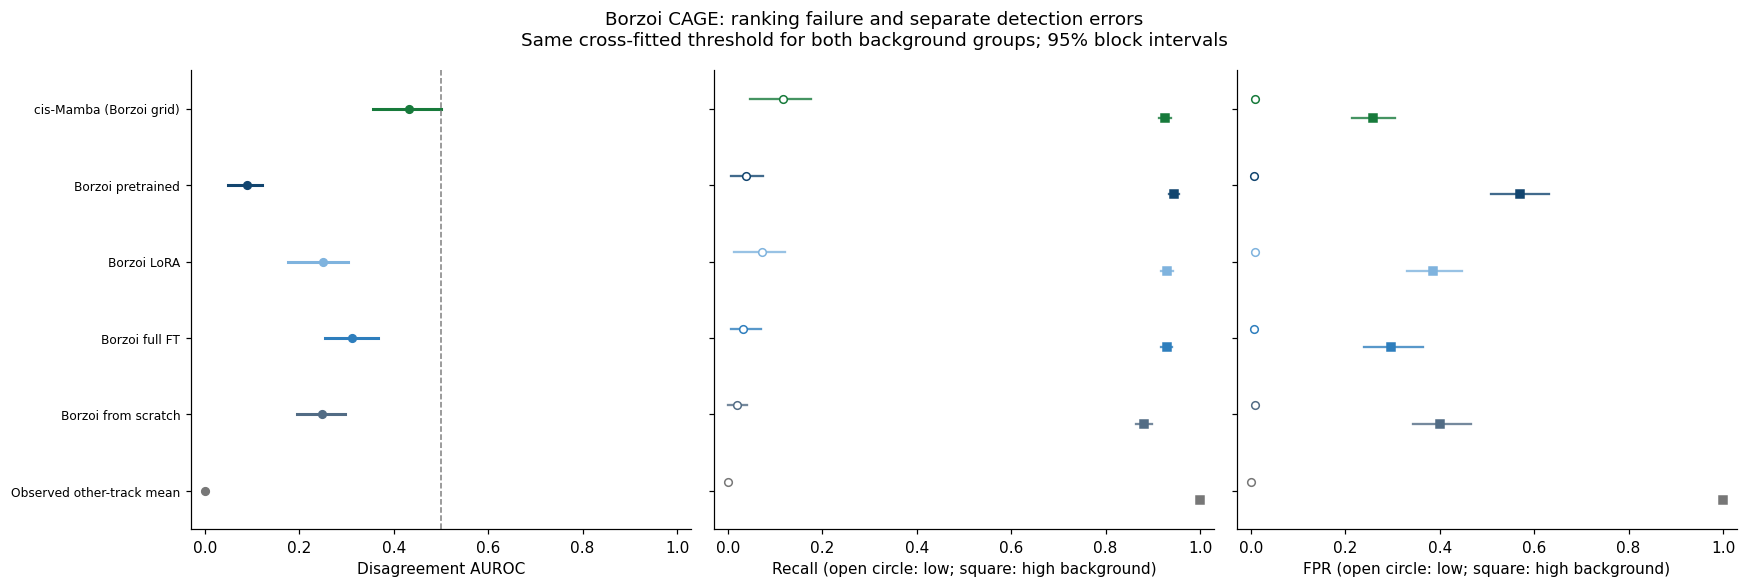

In [4]:
def savefig(fig,name):
    fig.savefig(OUT/f'{name}.png',dpi=160,bbox_inches='tight')
    plt.show()

def forest(ax,table,models,value='value',ideal=None):
    t=table.set_index('model')
    for i,m in enumerate(models):
        if m not in t.index:continue
        r=t.loc[m];v=r[value]
        if np.isfinite(v):
            ax.plot([r['lo'],r['hi']],[i,i],color=COLORS[m],lw=2)
            ax.plot(v,i,'o',color=COLORS[m],ms=5)
        else:ax.text(.02,i,'insufficient support',transform=ax.get_yaxis_transform(),fontsize=7)
    if ideal is not None:ax.axvline(ideal,color='.5',ls='--',lw=1)
    ax.set_yticks(range(len(models)),models,fontsize=8);ax.invert_yaxis()

for grid in BINS:
    models=MODELS[grid]+['Observed other-track mean']
    fig,axes=plt.subplots(1,3,figsize=(16,5.4),sharey=True)
    forest(axes[0],AUCS[(AUCS.grid==grid)&(AUCS.subset=='Disagreement R2')],models,'auroc',.5)
    axes[0].set(xlabel='Disagreement AUROC',xlim=(-.03,1.03))
    for ax,metric in zip(axes[1:],['Recall','FPR']):
        for bg,marker,offset in [('Low','o',-.12),('High','s',.12)]:
            t=RATES[(RATES.grid==grid)&(RATES.metric==metric)&(RATES.background==bg)].set_index('model')
            for i,m in enumerate(models):
                r=t.loc[m]
                ax.plot([r.lo,r.hi],[i+offset,i+offset],color=COLORS[m],alpha=.8)
                ax.plot(r.value,i+offset,marker,color=COLORS[m],ms=5,mfc=COLORS[m] if bg=='High' else 'white')
        ax.set(xlabel=metric+' (open circle: low; square: high background)',xlim=(-.03,1.03))
    axes[0].set_ylim(len(models)-.5,-.5)
    fig.suptitle(grid+' CAGE: ranking failure and separate detection errors\nSame cross-fitted threshold for both background groups; 95% block intervals')
    fig.tight_layout();savefig(fig,grid.lower()+'_classification')

## 3. Signed errors and directional attraction

For promoter log expression, `d=y−mu` and `e=prediction−y`. Plot mean `e` across specificity deciles.
A descriptive mixture `prediction=(1−lambda)y+lambda*mu` yields `e=−lambda*d`.
Report both sides separately (`d≥1`, `d≤−1`), not just a pooled slope.

Also report the fraction whose prediction falls **strictly between** the observation and the
reference mean, for `|d|≥1`. This distinguishes movement toward the mean from crossing beyond it,
but is not a causal or noise-corrected estimate. The mean baseline lies at the endpoint and is not
counted as strictly between. A zero-expression control exposes generic underprediction.

A negative error slope alone is insufficient: expression noise appears with opposite signs in
`d` and `e`. No observed-reference correlation is used as the headline specificity result.

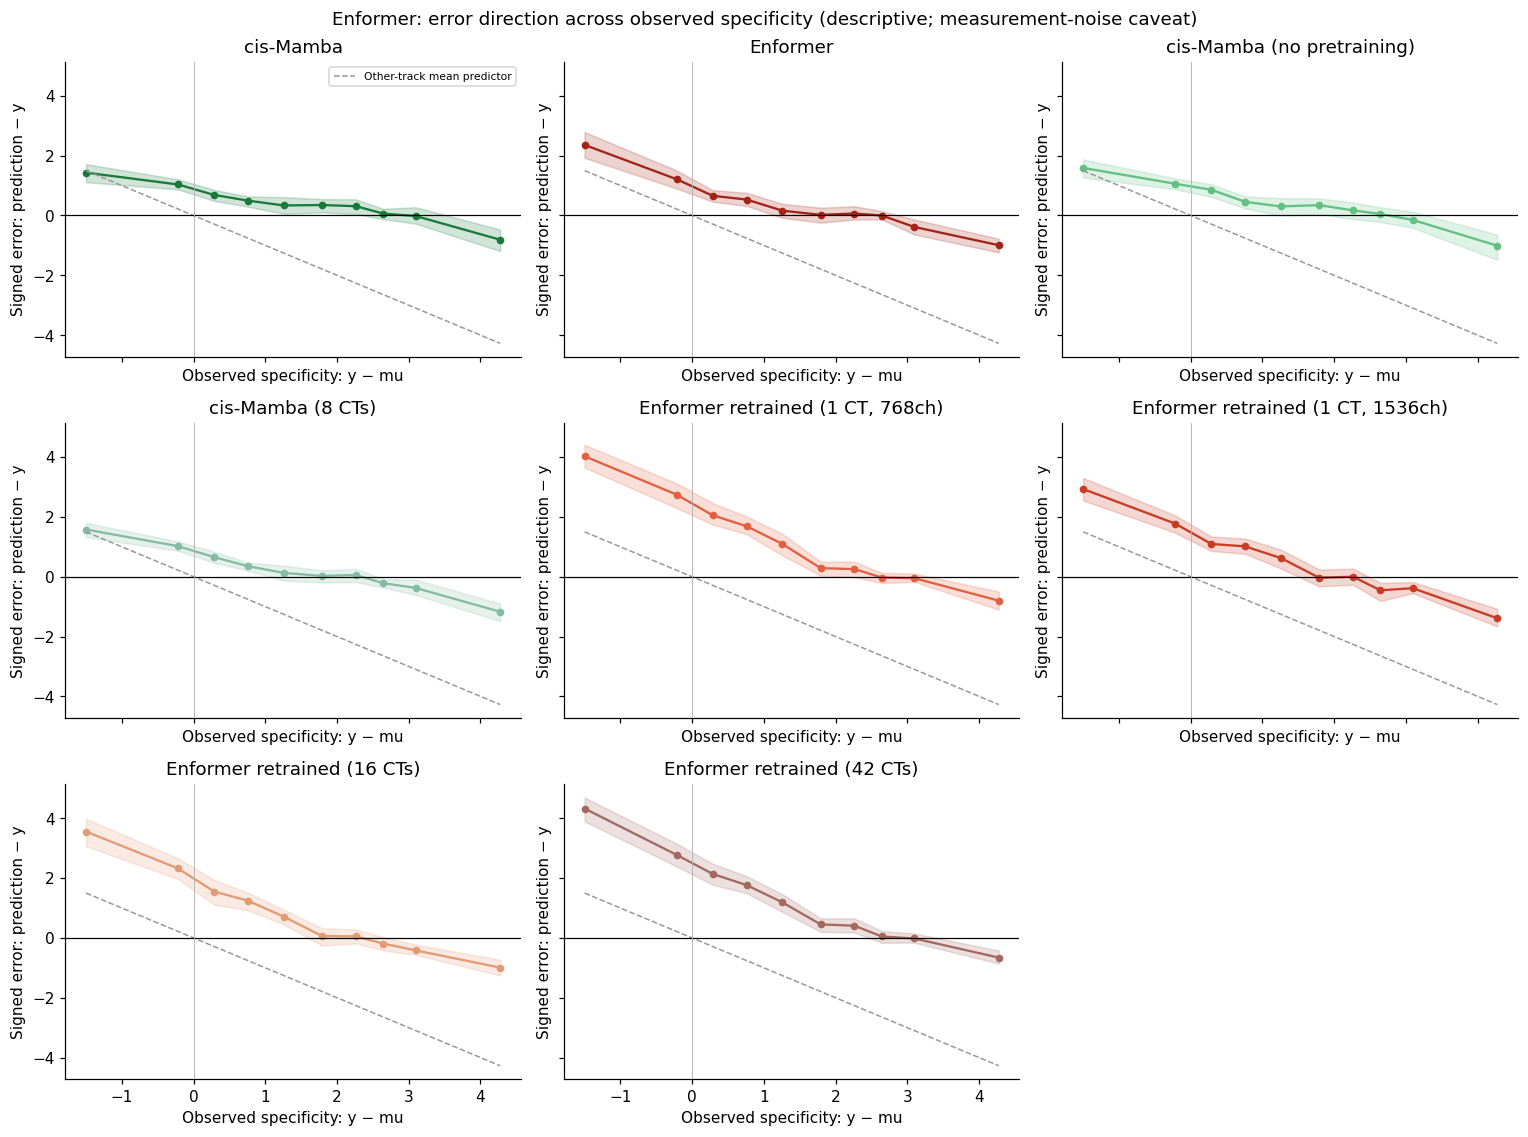

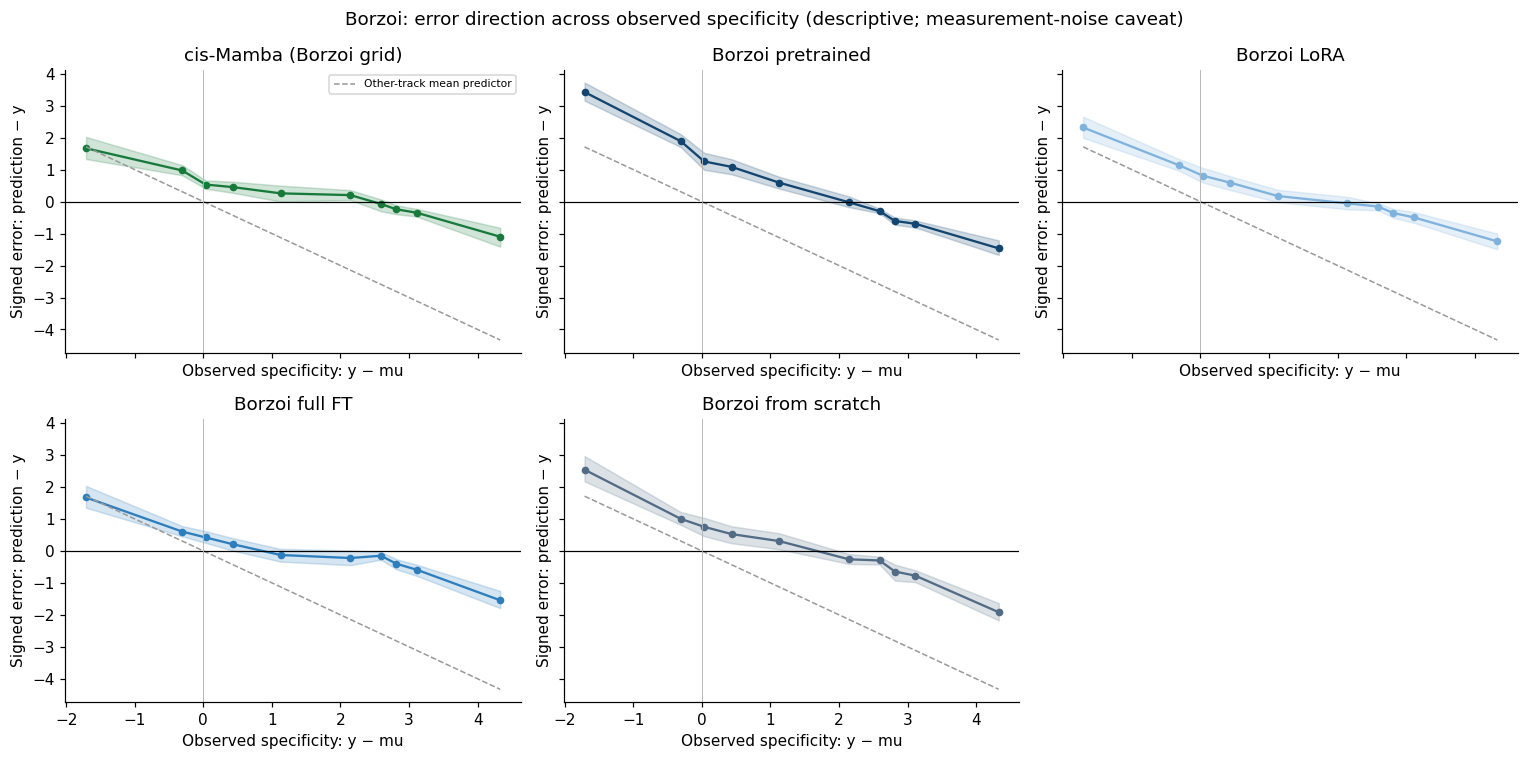

,grid,model,metric,value,lo,hi,n
2,Enformer,cis-Mamba,Above reference (d >= 1),0.043,-0.139,0.175,1083
3,Enformer,cis-Mamba,Below reference (d <= -1),1.599,1.231,1.936,98
7,Enformer,Enformer,Above reference (d >= 1),-0.183,-0.280,-0.077,1083
8,Enformer,Enformer,Below reference (d <= -1),2.663,2.178,3.240,98
12,Enformer,cis-Mamba (no pretraining),Above reference (d >= 1),-0.046,-0.241,0.107,1083
13,Enformer,cis-Mamba (no pretraining),Below reference (d <= -1),1.620,1.285,1.905,98
17,Enformer,cis-Mamba (8 CTs),Above reference (d >= 1),-0.255,-0.379,-0.153,1083
18,Enformer,cis-Mamba (8 CTs),Below reference (d <= -1),1.729,1.440,2.022,98
22,Enformer,"Enformer retrained (1 CT, 768ch)",Above reference (d >= 1),0.132,0.004,0.258,1083
23,Enformer,"Enformer retrained (1 CT, 768ch)",Below reference (d <= -1),4.224,3.697,4.800,98


In [5]:
def slope_boot(f,x,y):
    ids,w=boot_for(f);nb=w.shape[1];x=np.asarray(x,float);y=np.asarray(y,float)
    totals=np.column_stack([np.bincount(ids,weights=v,minlength=nb) for v in [np.ones(len(x)),x,y,x*x,x*y]])
    def solve(t):
        n,sx,sy,sxx,sxy=np.moveaxis(t,-1,0)
        with np.errstate(divide='ignore',invalid='ignore'):
            vx=sxx-sx*sx/n; result=(sxy-sx*sy/n)/vx
        return np.where(vx>1e-12,result,np.nan)
    return float(solve(totals.sum(axis=0))),solve(w@totals)

SIGNED_ROWS=[];CURVE_ROWS=[];SIGNED_DRAWS={}
for grid,f in FRAMES.items():
    d=f.d.to_numpy(); bins=pd.qcut(d,10,labels=False,duplicates='drop')
    for model in MODELS[grid]+['Observed other-track mean','Zero expression']:
        error=f[model].to_numpy()-f.y.to_numpy()
        mse,rmse_draws=mean_boot(f,error**2,np.ones(len(f),bool))
        lo,hi,valid=ci(np.sqrt(rmse_draws))
        SIGNED_ROWS.append(dict(grid=grid,model=model,metric='Promoter log RMSE',value=np.sqrt(mse),lo=lo,hi=hi,n=len(f),blocks=f.block.nunique()))
        slope,draws=slope_boot(f,d,error);lo,hi,valid=ci(draws)
        SIGNED_ROWS.append(dict(grid=grid,model=model,metric='Error slope versus specificity',value=slope,lo=lo,hi=hi,n=len(f),blocks=f.block.nunique()))
        SIGNED_DRAWS[grid,model,'Error slope versus specificity']=draws
        for label,mask in [('Above reference (d >= 1)',d>=1),('Below reference (d <= -1)',d<=-1)]:
            point,draws=mean_boot(f,error,mask)
            if not supported(f,mask):point=np.nan;draws[:]=np.nan
            lo,hi,valid=ci(draws)
            SIGNED_ROWS.append(dict(grid=grid,model=model,metric=label,value=point,lo=lo,hi=hi,n=int(mask.sum()),blocks=f.loc[mask,'block'].nunique()))
            SIGNED_DRAWS[grid,model,label]=draws
        movement=np.divide(-error,d,out=np.full(len(d),np.nan),where=np.abs(d)>0)
        between=(movement>0)&(movement<1)
        point,draws=mean_boot(f,between,np.abs(d)>=1);lo,hi,valid=ci(draws)
        SIGNED_ROWS.append(dict(grid=grid,model=model,metric='Fraction strictly between truth and mean',value=point,lo=lo,hi=hi,n=int((np.abs(d)>=1).sum()),blocks=f.loc[np.abs(d)>=1,'block'].nunique()))
        for b in np.unique(bins):
            mask=bins==b;point,draws=mean_boot(f,error,mask);lo,hi,valid=ci(draws)
            CURVE_ROWS.append(dict(grid=grid,model=model,decile=int(b),d_mean=float(d[mask].mean()),error=point,lo=lo,hi=hi,n=int(mask.sum())))
SIGNED=pd.DataFrame(SIGNED_ROWS);CURVES=pd.DataFrame(CURVE_ROWS)
for grid in FRAMES:
    models=MODELS[grid];ncols=3;nrows=int(np.ceil(len(models)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(14,3.5*nrows),sharex=True,sharey=True,squeeze=False)
    for ax,model in zip(axes.flat,models):
        t=CURVES[(CURVES.grid==grid)&(CURVES.model==model)]
        ax.plot(t.d_mean,t.error,'o-',color=COLORS[model],ms=4)
        ax.fill_between(t.d_mean,t.lo,t.hi,color=COLORS[model],alpha=.2)
        ax.plot(t.d_mean,-t.d_mean,'--',color='.6',lw=1,label='Other-track mean predictor')
        ax.axhline(0,color='black',lw=.8);ax.axvline(0,color='.7',lw=.6)
        ax.set(title=model,xlabel='Observed specificity: y − mu',ylabel='Signed error: prediction − y')
    for ax in list(axes.flat)[len(models):]:ax.set_visible(False)
    axes.flat[0].legend(fontsize=7)
    fig.suptitle(grid+': error direction across observed specificity (descriptive; measurement-noise caveat)')
    fig.tight_layout();savefig(fig,grid.lower()+'_signed_errors')
display(SIGNED[SIGNED.metric.str.contains('reference')][['grid','model','metric','value','lo','hi','n']].round(3))

## 4. Expression-matched background association

Match on measured GM12878 log expression using fixed 0.5-log2-unit bins. Within each stratum,
fit `prediction = stratum_intercept + b_y*y + b_background*mu`. The continuous `y` term adjusts
remaining expression differences inside each stratum. Strata with fewer than ten genes are excluded.
This is **stratified statistical matching**, not one-to-one causal matching. It estimates whether
predictions retain background association after adjusting for measured expression. Export all
stratum assignments, counts, and background ranges; vary bin width in sensitivity analyses.

The coefficient is in predicted log units per background log unit. Perfect observed-expression
predictions have coefficient 0; the reference-mean predictor has coefficient 1. Negative values
mean inverse conditional association; **smaller is not automatically better**. This coefficient is
not a fraction of reliance on a shortcut. Unmeasured factors, expression noise, and target-scale
mismatch can explain associations. The block bootstrap recomputes within-stratum centering and
both coefficients in each draw.

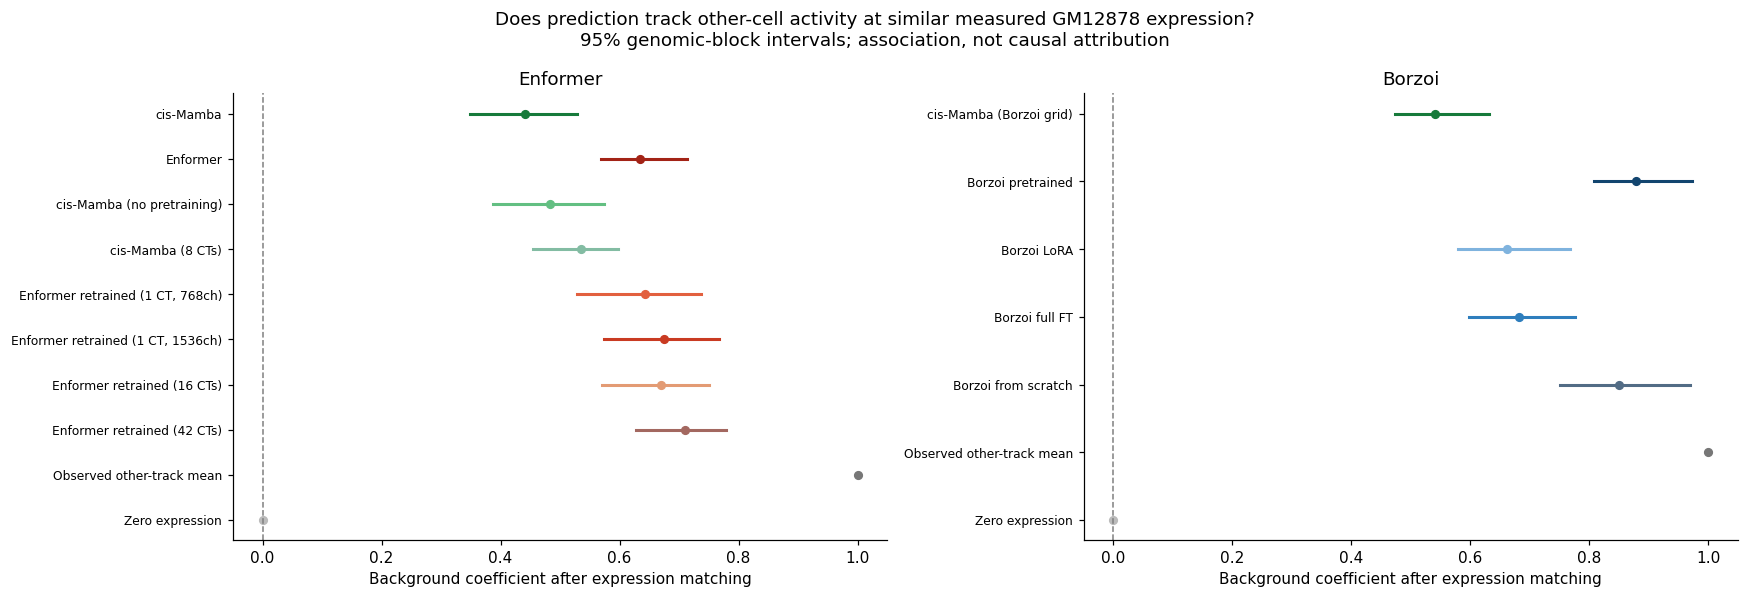

,grid,model,value,lo,hi,n,blocks,valid_draws
0,Enformer,cis-Mamba,0.440,0.348,0.528,1795,87,1000
1,Enformer,Enformer,0.635,0.568,0.713,1795,87,1000
2,Enformer,cis-Mamba (no pretraining),0.484,0.387,0.574,1795,87,1000
3,Enformer,cis-Mamba (8 CTs),0.535,0.455,0.598,1795,87,1000
4,Enformer,"Enformer retrained (1 CT, 768ch)",0.642,0.529,0.737,1795,87,1000
5,Enformer,"Enformer retrained (1 CT, 1536ch)",0.675,0.573,0.766,1795,87,1000
6,Enformer,Enformer retrained (16 CTs),0.669,0.570,0.751,1795,87,1000
7,Enformer,Enformer retrained (42 CTs),0.710,0.628,0.780,1795,87,1000
8,Enformer,Observed other-track mean,1.000,1.000,1.000,1795,87,1000
9,Enformer,Zero expression,0.000,0.000,0.000,1795,87,1000


n  blocks   y_min   y_max  background_min  background_max
grid     stratum                                                             
Borzoi   0        293      83   0.000   0.496           0.000           5.912
         1        175      69   0.506   0.993           0.087           5.058
         2        123      60   1.021   1.496           0.119           5.187
         3         95      59   1.501   1.993           0.188           4.903
         4         80      47   2.007   2.498           0.343           5.919
         5         58      36   2.511   2.986           0.325           5.408
         6         55      37   3.005   3.496           0.145           5.880
         7         54      31   3.508   3.991           0.799           6.073
         8         46      23   4.002   4.489           0.591           5.909
         9         30      25   4.544   4.994           0.510           6.450
         10        21      16   5.001   5.458           0.293           5.789
         11        28      23   5.521   5.988           0.651           6.005
         12        27      15   6.083   6.500           1.985           5.638
         13        38      22   6.523   6.987           0.722           6.167
         14        64      34   7.007   7.484           0.744           6.021
         15       110      47   7.510   8.000           0.950           6.409
         16       182      65   8.000   8.499           1.437           7.246
         17       227      69   8.502   9.000           1.794           6.799
         18       155      67   9.000   9.490           1.227           7.315
         19        59      31   9.501   9.997           0.693           7.515
         20        11      11  10.000  10.482           5.903           7.364
Enformer 0        137      44   0.000   0.498           0.006           3.602
         1        164      42   0.505   1.000           0.171           6.609
         2        134      41   1.001   1.498           0.228           5.672
         3        127      39   1.501   1.999           0.250           6.214
         4         95      38   2.001   2.487           0.314           6.700
         5         58      27   2.502   2.999           0.460           5.801
         6         39      23   3.004   3.490           0.397           4.758
         7         41      23   3.522   3.997           0.466           5.242
         8         33      21   4.058   4.496           0.607           6.185
         9         43      22   4.536   4.982           1.665           7.031
         10        40      21   5.012   5.493           0.300           5.720
         11        26      17   5.510   5.988           0.905           6.153
         12        45      20   6.003   6.495           2.074           5.882
         13        50      23   6.513   6.997           0.547           5.883
         14        69      22   7.007   7.499           1.248           7.626
         15        70      29   7.500   7.999           2.321           7.841
         16        91      32   8.009   8.498           0.982           7.207
         17       204      47   8.509   8.996           2.384           8.395
         18       158      39   9.001   9.499           2.213           8.521
         19       127      29   9.503   9.998           1.098           8.891
         20        44      17  10.000  10.484           1.914           9.118

In [6]:
def conditional_background(f,pred,width=.5,reference='mu',n_boot=N_BOOT):
    y=f.y.to_numpy();mu=f[reference].to_numpy();pred=np.asarray(pred,float)
    group=np.floor(y/width).astype(int)
    counts=pd.Series(group).value_counts()
    keep=np.isin(group,counts[counts>=10].index)
    ff=f.loc[keep].reset_index(drop=True)
    y,mu,pred,group=y[keep],mu[keep],pred[keep],group[keep]
    if len(ff)<MIN_N or ff.block.nunique()<MIN_BLOCKS:return np.nan,np.full(n_boot,np.nan),keep
    _,sid=np.unique(group,return_inverse=True);ns=sid.max()+1
    bid,w=boot_for(ff,n_boot);nb=w.shape[1]
    terms=[np.ones(len(ff)),y,mu,pred,y*y,mu*mu,y*mu,y*pred,mu*pred]
    stats=np.stack([np.bincount(bid*ns+sid,weights=v,minlength=nb*ns).reshape(nb,ns) for v in terms],axis=-1)
    def solve(t):
        n,sy,sm,sp,syy,smm,sym,syp,smp=np.moveaxis(t,-1,0)
        safe=np.where(n>0,n,1)
        yy=np.sum(syy-sy*sy/safe,axis=-1)
        mm=np.sum(smm-sm*sm/safe,axis=-1)
        ym=np.sum(sym-sy*sm/safe,axis=-1)
        yp=np.sum(syp-sy*sp/safe,axis=-1)
        mp=np.sum(smp-sm*sp/safe,axis=-1)
        determinant=yy*mm-ym*ym
        with np.errstate(divide='ignore',invalid='ignore'):coef=(mp*yy-yp*ym)/determinant
        return np.where(determinant>1e-10,coef,np.nan)
    point=float(solve(stats.sum(axis=0)))
    draws=solve((w@stats.reshape(nb,-1)).reshape(len(w),ns,9))
    return point,draws,keep

MATCH_ROWS=[];MATCH_DRAWS={};MATCH_SUPPORT=[]
for grid,f in FRAMES.items():
    for model in MODELS[grid]+['Observed other-track mean','Zero expression']:
        point,draws,keep=conditional_background(f,f[model]);lo,hi,valid=ci(draws)
        MATCH_ROWS.append(dict(grid=grid,model=model,value=point,lo=lo,hi=hi,n=int(keep.sum()),blocks=f.loc[keep,'block'].nunique(),valid_draws=valid))
        MATCH_DRAWS[grid,model]=draws
    s=f[['gene_id','block','y','mu']].copy();s['stratum']=np.floor(s.y/.5).astype(int)
    s['included']=keep;s['grid']=grid
    MATCH_SUPPORT.append(s)
MATCHED=pd.DataFrame(MATCH_ROWS)
fig,axes=plt.subplots(1,2,figsize=(16,5.5))
for ax,grid in zip(axes,FRAMES):
    forest(ax,MATCHED[MATCHED.grid==grid],MODELS[grid]+['Observed other-track mean','Zero expression'],ideal=0)
    ax.set(title=grid,xlabel='Background coefficient after expression matching')
fig.suptitle('Does prediction track other-cell activity at similar measured GM12878 expression?\n95% genomic-block intervals; association, not causal attribution')
fig.tight_layout();savefig(fig,'expression_matched_background')
display(MATCHED.round(3))
display(pd.concat(MATCH_SUPPORT).query('included').groupby(['grid','stratum']).agg(n=('gene_id','size'),blocks=('block','nunique'),y_min=('y','min'),y_max=('y','max'),background_min=('mu','min'),background_max=('mu','max')).round(3))

## 5. Paired contrasts and robustness

Every contrast is **left minus right** with shared block draws. Report the same-arm high-minus-low
background changes in recall/FPR and specialist-minus-pretrained changes in each stratum. Higher
recall/AUROC and lower FPR are favorable. Signed-error slopes and background coefficients have no
universal “larger is better” interpretation. These intervals are descriptive, not corrected for
multiple comparisons.

Sensitivity settings are fixed before reading scores: active/silent cutoffs (0.5/0.1, 1/0.2, 2/0.4),
background quantiles (p50/p90, p25/p75, p50/p80), promoter half-width (256/512/1024), expression-matching
bin widths (0.25/0.5/1), mean-of-logs versus log-of-mean reference, exclusion of overlapping promoters,
and the strict Borzoi no-input/training-label-overlap subset. No sensitivity setting replaces the
primary analysis. Suppressed estimates remain visible with counts.

In [7]:
PAIRED=[]
for grid in BINS:
    cis=MODELS[grid][0];base='Enformer' if grid=='Enformer' else 'Borzoi pretrained'
    rates=RATES[RATES.grid==grid].set_index(['model','metric','background'])
    for model in MODELS[grid]:
        for metric in ['Recall','FPR']:
            diff=RATE_DRAWS[grid,model,metric,'High']-RATE_DRAWS[grid,model,metric,'Low']
            lo,hi,valid=ci(diff)
            point=rates.loc[(model,metric,'High'),'value']-rates.loc[(model,metric,'Low'),'value']
            PAIRED.append(dict(grid=grid,comparison='High minus low background',left=model,right=model,metric=metric,stratum='Within model',difference=point,lo=lo,hi=hi,valid_draws=valid))
    for model in MODELS[grid]:
        if model==cis:continue
        for metric in ['Recall','FPR']:
            for bg in ['All','Low','High']:
                diff=RATE_DRAWS[grid,cis,metric,bg]-RATE_DRAWS[grid,model,metric,bg];lo,hi,valid=ci(diff)
                point=rates.loc[(cis,metric,bg),'value']-rates.loc[(model,metric,bg),'value']
                PAIRED.append(dict(grid=grid,comparison='Specialist minus comparator',left=cis,right=model,metric=metric,stratum=bg,difference=point,lo=lo,hi=hi,valid_draws=valid))
        for subset in ['All classified promoter bins','Disagreement R2']:
            diff=AUC_DRAWS[grid,cis,subset]-AUC_DRAWS[grid,model,subset];lo,hi,valid=ci(diff)
            t=AUCS[(AUCS.grid==grid)&(AUCS.subset==subset)].set_index('model')
            PAIRED.append(dict(grid=grid,comparison='Specialist minus comparator',left=cis,right=model,metric='AUROC',stratum=subset,difference=t.loc[cis,'auroc']-t.loc[model,'auroc'],lo=lo,hi=hi,valid_draws=valid))
        diff=MATCH_DRAWS[grid,cis]-MATCH_DRAWS[grid,model];lo,hi,valid=ci(diff)
        t=MATCHED[MATCHED.grid==grid].set_index('model')
        PAIRED.append(dict(grid=grid,comparison='Specialist minus comparator',left=cis,right=model,metric='Background coefficient',stratum='Expression matched',difference=t.loc[cis,'value']-t.loc[model,'value'],lo=lo,hi=hi,valid_draws=valid))
PAIRED=pd.DataFrame(PAIRED)
display(PAIRED[(PAIRED.comparison=='High minus low background')][['grid','left','metric','difference','lo','hi']].round(3))

SENS=[]
for grid,f in BINS.items():
    for active,silent,lq,hq in [(1,.2,.5,.9),(.5,.1,.5,.9),(2,.4,.5,.9),(1,.2,.25,.75),(1,.2,.5,.8)]:
        pos,neg,low,high,cut=groups(f,active,silent,lq,hq);p=pos&low;n=neg&high;k=p|n
        for model in MODELS[grid]:
            ok=supported(f,p) and supported(f,n)
            val=weighted_auc(f.loc[k,model],p[k]) if ok else np.nan
            SENS.append(dict(grid=grid,model=model,analysis='Bin disagreement AUROC',setting=f'active={active};silent={silent};q={lq},{hq}',value=val,n=int(k.sum()),n_positive=int(p.sum()),n_negative=int(n.sum()),status='estimated' if ok else 'insufficient support'))
    # Promoter-level analogue: average native-bin signal, not summed signal at bin cutoffs.
    p,a=PANELS[grid];keep=p['pad'].to_numpy()==512
    pf=FRAMES[grid].copy();nbins=(pf.bin_end-pf.bin_start).to_numpy()
    raw=a['measured'][keep];pf['truth']=raw[:,435]/nbins
    pf['background']=np.delete(raw,435,axis=1).mean(axis=1)/nbins
    pos,neg,low,high,cut=groups(pf);positive=pos&low;negative=neg&high;k=positive|negative
    for model in MODELS[grid]:
        ok=supported(pf,positive) and supported(pf,negative)
        val=weighted_auc(pf.loc[k,model],positive[k]) if ok else np.nan
        SENS.append(dict(grid=grid,model=model,analysis='Promoter disagreement AUROC',setting='mean native-bin signal; active=1;silent=.2;q=.5,.9',value=val,n=int(k.sum()),n_positive=int(positive.sum()),n_negative=int(negative.sum()),status='estimated' if ok else 'insufficient support'))

for grid,(p,a) in PANELS.items():
    settings=[(512,.5,'mean_log','All'),(256,.5,'mean_log','All'),(1024,.5,'mean_log','All'),
              (512,.25,'mean_log','All'),(512,1.,'mean_log','All'),(512,.5,'log_mean','All'),
              (512,.5,'mean_log','Nonoverlapping promoters')]
    if grid=='Borzoi':settings.append((512,.5,'mean_log','Strict no input-label overlap'))
    for pad,width,reference,selection in settings:
        keep=p['pad'].to_numpy()==pad;f=p.loc[keep].reset_index(drop=True).copy();raw=a['measured'][keep]
        f['y']=np.log2(raw[:,435]+1);others=np.delete(raw,435,axis=1)
        f['mu']=np.log2(others+1).mean(1) if reference=='mean_log' else np.log2(others.mean(1)+1)
        mask=np.ones(len(f),bool)
        if selection=='Nonoverlapping promoters':mask=~f.ambiguous_promoter.to_numpy()
        if selection=='Strict no input-label overlap':mask=f.strict_no_input_label_overlap.to_numpy()
        for model in MODELS[grid]:
            pred=np.log2(a[model][keep]+1)
            ff=f.loc[mask].reset_index(drop=True)
            point,_,used=conditional_background(ff,pred[mask],width=width,n_boot=0)
            slope,_=slope_boot(ff,ff.y-ff.mu,pred[mask]-ff.y)
            setting=f'pad={pad};width={width};reference={reference};{selection}'
            for analysis,value in [('Expression-matched background coefficient',point),('Signed-error slope',slope)]:
                SENS.append(dict(grid=grid,model=model,analysis=analysis,setting=setting,value=value,n=int(used.sum()) if analysis=='Expression-matched background coefficient' else len(ff),status='estimated' if np.isfinite(value) else 'undefined'))
SENS=pd.DataFrame(SENS)
display(SENS[SENS.analysis.str.contains('disagreement')][['grid','analysis','setting','n_positive','n_negative','status']].drop_duplicates())

,grid,left,metric,difference,lo,hi
0,Enformer,cis-Mamba,Recall,0.662,0.575,0.743
1,Enformer,cis-Mamba,FPR,0.126,0.010,0.249
2,Enformer,Enformer,Recall,0.808,0.770,0.843
3,Enformer,Enformer,FPR,0.320,0.175,0.453
4,Enformer,cis-Mamba (no pretraining),Recall,0.674,0.611,0.735
5,Enformer,cis-Mamba (no pretraining),FPR,0.101,0.030,0.189
6,Enformer,cis-Mamba (8 CTs),Recall,0.761,0.723,0.800
7,Enformer,cis-Mamba (8 CTs),FPR,0.177,0.059,0.297
8,Enformer,"Enformer retrained (1 CT, 768ch)",Recall,0.820,0.793,0.848
9,Enformer,"Enformer retrained (1 CT, 768ch)",FPR,0.362,0.226,0.502


,grid,analysis,setting,n_positive,n_negative,status
0,Enformer,Bin disagreement AUROC,"active=1;silent=0.2;q=0.5,0.9",627.0,44.0,estimated
8,Enformer,Bin disagreement AUROC,"active=0.5;silent=0.1;q=0.5,0.9",1136.0,33.0,estimated
16,Enformer,Bin disagreement AUROC,"active=2;silent=0.4;q=0.5,0.9",271.0,62.0,estimated
24,Enformer,Bin disagreement AUROC,"active=1;silent=0.2;q=0.25,0.75",43.0,332.0,estimated
32,Enformer,Bin disagreement AUROC,"active=1;silent=0.2;q=0.5,0.8",627.0,219.0,estimated
40,Enformer,Promoter disagreement AUROC,mean native-bin signal; active=1;silent=.2;q=....,245.0,1.0,insufficient support
48,Borzoi,Bin disagreement AUROC,"active=1;silent=0.2;q=0.5,0.9",155.0,936.0,estimated
53,Borzoi,Bin disagreement AUROC,"active=0.5;silent=0.1;q=0.5,0.9",563.0,848.0,estimated
58,Borzoi,Bin disagreement AUROC,"active=2;silent=0.4;q=0.5,0.9",31.0,1023.0,estimated
63,Borzoi,Bin disagreement AUROC,"active=1;silent=0.2;q=0.25,0.75",21.0,4804.0,estimated


### All-transcript-TSS sensitivity: closer to model7's population

**This population sensitivity was added after the first representative-promoter results were inspected**, to investigate the difference from model7. It does not replace the primary population.

The main bin test above inherits model8's representative promoters. This check instead uses **every
protein-coding annotated transcript TSS ±500 bp**, on the same 1,837 sequence-aligned Enformer regions,
with the same ≥1/<0.2 activity cutoffs and p50/p90 background rule. It excludes the three edge-shifted
regions and uses the correct minus-strand coordinate `end0−1`; therefore it is close to, but not an
exact rerun of, model7's 1,840-region CAGE analysis. Original arrays are rescored, not cached AUROCs.
The counts and scores of both populations are shown together. Do not choose the population based on
which produces the more favorable result. The Borzoi analyses remain on the stated representative-
promoter population; there is no claim of an all-transcript Borzoi replication here.

In [8]:
regions=pd.read_csv(BASE/'retained_regions.tsv',sep='\t')
assert len(regions)==1837 and not regions.edge_shifted.any()
annotation=pd.read_parquet(DATA/'DE_danwei/gencode.v49.annotation.gtf.exon_transcript__protein_coding.parquet')
annotation=annotation[annotation.feature=='transcript'].copy()
annotation['tss']=np.where(annotation.strand=='+',annotation.start0,annotation.end0-1)
centers=regions.output_start.to_numpy()[:,None]+np.arange(896)[None,:]*128+64
mask=np.zeros(centers.shape,bool)
for chrom,g in annotation.groupby('chrom'):
    rows=np.flatnonzero(regions.chrom.to_numpy()==chrom)
    if len(rows)==0:continue
    ts=np.sort(g.tss.to_numpy());c=centers[rows];j=np.searchsorted(ts,c)
    distances=np.minimum(np.abs(c-ts[np.clip(j-1,0,len(ts)-1)]),np.abs(c-ts[np.clip(j,0,len(ts)-1)]))
    mask[rows]=distances<=500
# Connected input components over the entire transcript-bin population.
blockmap={};block=-1;lastchrom=None;end=-1
for row in regions.sort_values(['chrom','rna_start']).itertuples():
    start=int(row.rna_start);stop=start+524288
    if row.chrom!=lastchrom or start>=end:block+=1;end=stop
    else:end=max(end,stop)
    lastchrom=row.chrom;blockmap[row.enformer_row]=block
ri,bi=np.nonzero(mask)
tss=pd.DataFrame(dict(row=regions.enformer_row.to_numpy()[ri],bin=bi,chrom=regions.chrom.to_numpy()[ri],
    start=regions.output_start.to_numpy()[ri]+bi*128,strand='.'))
tss['block']=tss.row.map(blockmap)
tss=tss.drop_duplicates(['chrom','start']).reset_index(drop=True)
truth=np.load(MO/'GM12878_base_targets_conv.npy',mmap_mode='r')
avg=np.load(DATA/'enformer/data/avg_cage_test_all.npy',mmap_mode='r')
tss['truth']=truth[tss.row,tss.bin]
tss['background']=np.maximum((avg[tss.row,tss.bin].astype(float)*638-tss.truth)/637,0)
p,n,low,high,cut=groups(tss)
rows=[]
for model,(path,col) in {**E_SPECS,'Observed other-track mean':(None,None)}.items():
    score=tss.background.to_numpy() if path is None else extract(np.load(path,mmap_mode='r'),tss,'Enformer',col)
    for label,positive,negative in [('All classified promoter bins',p,n),('Disagreement R2',p&low,n&high)]:
        value,draws=auc_boot(tss,score,positive,negative);lo,hi,valid=ci(draws)
        rows.append(dict(population='All transcript TSS ±500',model=model,subset=label,auroc=value,lo=lo,hi=hi,
            n_positive=int(positive.sum()),n_negative=int(negative.sum()),positive_blocks=tss.loc[positive,'block'].nunique(),
            negative_blocks=tss.loc[negative,'block'].nunique(),valid_draws=valid))
ALL_TSS=pd.DataFrame(rows)
representative=AUCS[AUCS.grid=='Enformer'].copy();representative['population']='Representative promoters ±512'
POPULATIONS=pd.concat([representative,ALL_TSS],ignore_index=True)
display(POPULATIONS[['population','model','subset','auroc','lo','hi','n_positive','n_negative']].round(3))

,population,model,subset,auroc,lo,hi,n_positive,n_negative
0,Representative promoters ±512,cis-Mamba,All classified promoter bins,0.941,0.934,0.948,5230,6077
1,Representative promoters ±512,cis-Mamba,Disagreement R2,0.691,0.593,0.796,627,44
2,Representative promoters ±512,Enformer,All classified promoter bins,0.928,0.921,0.937,5230,6077
3,Representative promoters ±512,Enformer,Disagreement R2,0.550,0.449,0.676,627,44
4,Representative promoters ±512,cis-Mamba (no pretraining),All classified promoter bins,0.930,0.922,0.938,5230,6077
5,Representative promoters ±512,cis-Mamba (no pretraining),Disagreement R2,0.676,0.610,0.745,627,44
6,Representative promoters ±512,cis-Mamba (8 CTs),All classified promoter bins,0.937,0.931,0.945,5230,6077
7,Representative promoters ±512,cis-Mamba (8 CTs),Disagreement R2,0.528,0.445,0.613,627,44
8,Representative promoters ±512,"Enformer retrained (1 CT, 768ch)",All classified promoter bins,0.887,0.876,0.899,5230,6077
9,Representative promoters ±512,"Enformer retrained (1 CT, 768ch)",Disagreement R2,0.400,0.284,0.530,627,44


## 6. Checks that distinguish arithmetic effects from biological evidence

These checks validate the weighted AUROC, joint block resampling, and expression-matched coefficient
against independent calculations. A synthetic perfect predictor of latent expression illustrates why
noise in the evaluated observation alone produces a negative signed-error slope. This is a warning
about identifiability, not an estimate of noise in the real assays.

In [9]:
from scipy.stats import pearsonr
# Tied-score weighted AUROC versus explicitly expanded Mann–Whitney ranks.
s=np.array([0.,0.,1.,2.,2.,3.]);lab=np.array([0,1,0,1,0,1],bool);w=np.array([2,1,3,2,1,4])
ss=np.repeat(s,w);ll=np.repeat(lab,w);r=rankdata(ss)
expected=(r[ll].sum()-ll.sum()*(ll.sum()+1)/2)/(ll.sum()*(~ll).sum())
assert abs(weighted_auc(s,lab,w)-expected)<1e-12
# Mean block bootstrap versus one explicitly expanded block sample.
f=FRAMES['Enformer'];ids,weights=boot_for(f);v=f.y.to_numpy();mask=f.d.to_numpy()>0
point,draws=mean_boot(f,v,mask);expanded=np.repeat(np.arange(len(f)),weights[0,ids])
assert np.allclose(draws[0],v[expanded][mask[expanded]].mean())
# Conditional coefficient must recover ideal known predictors.
for grid,f in FRAMES.items():
    for pred,want in [(f.y.to_numpy(),0.),(f.mu.to_numpy(),1.),(.7*f.y.to_numpy()+.3*f.mu.to_numpy(),.3)]:
        point,_,_=conditional_background(f,pred,n_boot=0)
        assert np.isclose(point,want,atol=1e-8),(grid,point,want)
    # Independent design-matrix OLS check for one actual model.
    pred=f[MODELS[grid][0]].to_numpy();point,_,keep=conditional_background(f,pred,n_boot=0)
    group=np.floor(f.y.to_numpy()[keep]/.5).astype(int)
    X=np.column_stack([pd.get_dummies(group,dtype=float).to_numpy(),f.y.to_numpy()[keep],f.mu.to_numpy()[keep]])
    coef=np.linalg.lstsq(X,pred[keep],rcond=None)[0][-1]
    assert np.isclose(point,coef,atol=1e-8)
    assert np.allclose((f[MODELS[grid][0]]-f.mu)-(f.y-f.mu),f[MODELS[grid][0]]-f.y)
# A perfect latent-expression predictor still appears to shrink noisy observations.
rng=np.random.default_rng(SEED);mu=rng.normal(4,1,20000);latent=mu+rng.normal(0,1,20000)
obs=latent+rng.normal(0,1,20000);perfect_latent=latent
noise_slope=np.polyfit(obs-mu,perfect_latent-obs,1)[0]
assert -.55<noise_slope<-.45
print('All numerical checks passed.')
print(f'Synthetic perfect latent predictor: signed-error slope {noise_slope:.3f} (expected −0.5 from measurement noise).')

All numerical checks passed.
Synthetic perfect latent predictor: signed-error slope -0.494 (expected −0.5 from measurement noise).


## 7. What this run supports

The following interpretation is generated from the executed results. Counts, intervals, and sensitivity
results take precedence over a preferred story. Both-direction error patterns plus positive background
association would be consistent with mean-directed errors; they do not prove a multitask-learning
mechanism. A smaller coefficient or error slope by itself is not evidence of better predictions.

For publication, repeat in several cell types, verify export/checkpoint provenance and genomic splits,
use independent replicates for specificity selection, and compare matched-input specialist/multitask
training. Retain the unsupported promoter-disagreement result rather than tuning cutoffs until it works.

Related literature: [Kathail et al., Methods §2.3](https://academic.oup.com/bioinformatics/article/42/9/btag626/8767764) and [AlphaGenome, Extended Data Fig. 3](https://www.nature.com/articles/s41586-025-10014-0#Fig10). Their predicted-panel normalization differs from the observed-reference diagnostics here; the analyses above do not reproduce their scores.

In [10]:
lines=['# comparing_model9 — executed findings','']
for grid in FRAMES:
    base='Enformer' if grid=='Enformer' else 'Borzoi pretrained';cis=MODELS[grid][0]
    lines += [f'## {grid}-grid CAGE',f'{len(FRAMES[grid]):,} promoters; {len(BINS[grid]):,} unique promoter bins.','']
    for model in [base,cis]:
        a=AUCS[(AUCS.grid==grid)&(AUCS.model==model)&(AUCS.subset=='Disagreement R2')].iloc[0]
        c=MATCHED[(MATCHED.grid==grid)&(MATCHED.model==model)].iloc[0]
        s=SIGNED[(SIGNED.grid==grid)&(SIGNED.model==model)].set_index('metric')
        plus=s.loc['Above reference (d >= 1)'];minus=s.loc['Below reference (d <= -1)']
        lines.append(f'- **{model}:** disagreement AUROC {a.auroc:.3f} [{a.lo:.3f}, {a.hi:.3f}] '
                     f'({a.n_positive:,} active/low-background; {a.n_negative:,} silent/high-background bins). '
                     f'Mean error above reference {plus.value:.3f} [{plus.lo:.3f}, {plus.hi:.3f}]; '
                     f'below reference {minus.value:.3f} [{minus.lo:.3f}, {minus.hi:.3f}] log2 units. '
                     f'Expression-matched background coefficient {c.value:.3f} [{c.lo:.3f}, {c.hi:.3f}].')
    t=PAIRED[(PAIRED.grid==grid)&(PAIRED.left==cis)&(PAIRED.right==base)&(PAIRED.metric=='AUROC')&(PAIRED.stratum=='Disagreement R2')].iloc[0]
    lines += [f'- Paired specialist-minus-pretrained disagreement AUROC: {t.difference:.3f} [{t.lo:.3f}, {t.hi:.3f}].','']
t=ALL_TSS[(ALL_TSS.model=='Enformer')&(ALL_TSS.subset=='Disagreement R2')].iloc[0]
lines += ['## Population sensitivity',f'Enformer disagreement AUROC on all annotated transcript TSS bins is {t.auroc:.3f} [{t.lo:.3f}, {t.hi:.3f}], versus the representative-promoter result above. This population dependence limits blanket below-chance claims.','']
lines += ['## Limits','These are descriptive, single-measurement diagnostics. Cross-fitted detection thresholds are internally calibrated, '
          'not validated on independent model-validation predictions. The promoter-level disagreement test has too few silent/high-background '
          'cases and is suppressed. Input-modality, training, and checkpoint differences prevent causal claims about task count. '
          'Replicate selection/evaluation and matched training remain necessary for stronger claims.']
summary='\n'.join(lines)
display(Markdown(summary))

Outputs: /data1/lesliec/sarthak/caduceus/notebooks/model_eval/cage_rna/comparing_model9_results


# comparing_model9 — executed findings

## Enformer-grid CAGE
1,797 promoters; 13,320 unique promoter bins.

- **Enformer:** disagreement AUROC 0.550 [0.449, 0.676] (627 active/low-background; 44 silent/high-background bins). Mean error above reference -0.183 [-0.280, -0.077]; below reference 2.663 [2.178, 3.240] log2 units. Expression-matched background coefficient 0.635 [0.568, 0.713].
- **cis-Mamba:** disagreement AUROC 0.691 [0.593, 0.796] (627 active/low-background; 44 silent/high-background bins). Mean error above reference 0.043 [-0.139, 0.175]; below reference 1.599 [1.231, 1.936] log2 units. Expression-matched background coefficient 0.440 [0.348, 0.528].
- Paired specialist-minus-pretrained disagreement AUROC: 0.141 [0.024, 0.270].

## Borzoi-grid CAGE
1,934 promoters; 61,036 unique promoter bins.

- **Borzoi pretrained:** disagreement AUROC 0.089 [0.049, 0.121] (155 active/low-background; 936 silent/high-background bins). Mean error above reference -0.505 [-0.576, -0.426]; below reference 3.652 [3.378, 3.947] log2 units. Expression-matched background coefficient 0.878 [0.808, 0.972].
- **cis-Mamba (Borzoi grid):** disagreement AUROC 0.432 [0.356, 0.501] (155 active/low-background; 936 silent/high-background bins). Mean error above reference -0.260 [-0.350, -0.195]; below reference 1.868 [1.477, 2.270] log2 units. Expression-matched background coefficient 0.541 [0.473, 0.631].
- Paired specialist-minus-pretrained disagreement AUROC: 0.344 [0.279, 0.409].

## Population sensitivity
Enformer disagreement AUROC on all annotated transcript TSS bins is 0.356 [0.314, 0.385], versus the representative-promoter result above. This population dependence limits blanket below-chance claims.

## Limits
These are descriptive, single-measurement diagnostics. Cross-fitted detection thresholds are internally calibrated, not validated on independent model-validation predictions. The promoter-level disagreement test has too few silent/high-background cases and is suppressed. Input-modality, training, and checkpoint differences prevent causal claims about task count. Replicate selection/evaluation and matched training remain necessary for stronger claims.